# Notification Fatigue Optimization: Stateful A/B Simulation

**Goal:** Compare user-randomized send policies with chronological consent, fatigue and exposure state. These are conditional synthetic scenarios, not observed randomized product outcomes.

## Imports

Load the approved libraries for modeling, simulation, statistical testing, and visualization.

In [1]:
from pathlib import Path
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 60)
plt.style.use("seaborn-v0_8")
sns.set_palette("husl")

In [ ]:
# Self-contained analysis helpers integrated from the former phase modules.

# Only the dependency closure used by this notebook is included.

from dataclasses import dataclass, asdict
import heapq
import json
from scipy.special import expit
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

OBSERVATION_END = pd.Timestamp("2026-04-01")

KEY = ["user_id", "event_timestamp"]

CHURN_METADATA = [
    "source_churn_target", "source_no_app_open_next_30d", "churn_status",
    "churn_witness_event_timestamp", "churn_witness_latest_open",
    "churn_window_complete_calendar", "churn_model_eligible",
]

def validate_churn_labels(raw, observation_end=OBSERVATION_END):
    """Retain only evidence-backed negatives; never infer inactivity from silence."""
    frame = raw.copy().reset_index(drop=True)
    frame["event_timestamp"] = pd.to_datetime(frame["event_timestamp"], errors="raise")
    if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
        raise ValueError("Churn evidence requires unique, nonmissing event keys")
    if "source_churn_target" in frame:
        raise ValueError("Pass immutable raw events, not an already validated table")
    frame["source_churn_target"] = frame["churn_target"]
    frame["source_no_app_open_next_30d"] = frame["no_app_open_next_30d"]
    witness = pd.Series(pd.NaT, index=frame.index, dtype="datetime64[ns]")
    for _, group in frame.groupby("user_id", sort=False):
        opens = np.sort(group.loc[group["app_opened_24h"].eq(True), "event_timestamp"].to_numpy())
        times = group["event_timestamp"].to_numpy()
        # A later event strictly more than 24h after t avoids overlap ambiguity.
        # Its entire possible open interval must lie inside (t, t + 30d].
        positions = np.searchsorted(opens, times + np.timedelta64(1, "D"), side="right")
        available = positions < len(opens)
        selected = np.full(len(group), np.datetime64("NaT"), dtype="datetime64[ns]")
        selected[available] = opens[positions[available]]
        inside = available & (selected + np.timedelta64(1, "D") <= times + np.timedelta64(30, "D"))
        selected[~inside] = np.datetime64("NaT")
        witness.loc[group.index] = selected
    frame["churn_witness_event_timestamp"] = witness
    frame["churn_witness_latest_open"] = witness + pd.Timedelta(days=1)
    mature = frame["event_timestamp"] + pd.Timedelta(days=30) <= pd.Timestamp(observation_end)
    frame["churn_window_complete_calendar"] = mature
    source_missing = frame[["source_churn_target", "source_no_app_open_next_30d"]].isna().any(axis=1)
    supported = mature & ~source_missing & witness.notna()
    frame["churn_status"] = "unverified_incomplete_activity_history"
    frame.loc[~mature, "churn_status"] = "censored_window"
    frame.loc[source_missing, "churn_status"] = "source_missing_preserved"
    frame.loc[supported, "churn_status"] = "verified_future_open_negative"
    corrected = pd.Series(pd.NA, index=frame.index, dtype="Float64")
    corrected.loc[supported] = 0.0
    frame["churn_target"] = corrected
    frame["no_app_open_next_30d"] = corrected.copy()
    # Observing a subset of negatives does not create a representative risk set.
    frame["churn_model_eligible"] = False
    assert_validated_churn(frame)
    return frame

def assert_validated_churn(frame):
    """Fail closed on unverified targets, positive claims, or missing witnesses."""
    required = CHURN_METADATA + ["churn_target", "no_app_open_next_30d"]
    if not set(required).issubset(frame.columns):
        raise ValueError("Unvalidated churn labels: use load_events()")
    observed = frame["churn_target"].notna()
    if frame.loc[observed, "churn_target"].ne(0).any():
        raise ValueError("Positive churn cannot be established from incomplete activity")
    if frame["churn_model_eligible"].any():
        raise ValueError("No complete activity-history population is available")
    if not frame["churn_target"].equals(frame["no_app_open_next_30d"]):
        raise ValueError("Canonical churn columns disagree")
    if not frame.loc[observed, "churn_status"].eq("verified_future_open_negative").all():
        raise ValueError("Unverified label cannot be retained")
    t = pd.to_datetime(frame.loc[observed, "event_timestamp"])
    w = pd.to_datetime(frame.loc[observed, "churn_witness_event_timestamp"])
    if not ((w > t + pd.Timedelta(days=1)) & (w + pd.Timedelta(days=1) <= t + pd.Timedelta(days=30))).all():
        raise ValueError("Churn witness outside conservative future-activity window")
    if frame.loc[frame["source_churn_target"].isna(), "churn_target"].notna().any():
        raise ValueError("Source missingness must be preserved")

def load_events(project_dir):
    """Load original events through the mandatory churn-validation boundary."""
    return validate_churn_labels(pd.read_csv(Path(project_dir) / "data/raw/notification_events.csv"))

SPLIT_DATE = pd.Timestamp("2026-03-01")

@dataclass(frozen=True)
class SimulationConfig:
    start: pd.Timestamp = SPLIT_DATE
    end: pd.Timestamp = OBSERVATION_END
    open_hour: int = 8
    close_hour: int = 20
    retry_hour: int = 9
    expiry_hours: int = 72
    seed: int = 42

    def __post_init__(self):
        if not (0 <= self.open_hour <= self.retry_hour <= self.close_hour <= 23):
            raise ValueError("Invalid local delivery hours")
        if self.start >= self.end or self.expiry_hours <= 0:
            raise ValueError("Invalid simulation interval/expiry")

@dataclass(frozen=True)
class FatigueDynamics:
    daily_retention: float
    engaged_increment: float
    ignored_increment: float
    initial_fallback: float

def fit_fatigue_dynamics(history):
    """Estimate a training-only approximation, not the unknown source generator."""
    h = history.sort_values(KEY).copy()
    previous = h.groupby("user_id")["fatigue_after_event"].shift()
    gaps = h.groupby("user_id")["event_timestamp"].diff()
    # Calendar days match the observed simulation's discrete daily context.
    dates = h["event_timestamp"].dt.normalize()
    day_gaps = dates.groupby(h["user_id"]).diff().dt.days
    valid = previous.gt(0) & h["fatigue_before_send"].gt(0) & day_gaps.gt(0) & gaps.notna()
    log_retention = np.log(h.loc[valid, "fatigue_before_send"] / previous[valid]) / day_gaps[valid]
    if not len(log_retention):
        raise ValueError("Insufficient pre-period transitions to estimate fatigue decay")
    decay = float(np.exp(log_retention.median()))
    delta = h["fatigue_after_event"] - h["fatigue_before_send"]
    engaged = delta[h["delivered"] & h["engaged_24h"]]
    ignored = delta[h["delivered"] & ~h["engaged_24h"]]
    if engaged.empty or ignored.empty or not 0 < decay <= 1:
        raise ValueError("Unsupported training fatigue transition")
    first = h.groupby("user_id", sort=False).head(1)["fatigue_before_send"]
    dynamics = FatigueDynamics(decay, float(engaged.median()), float(ignored.median()), float(first.median()))
    prediction = previous[valid] * decay ** day_gaps[valid]
    diagnostics = {
        **asdict(dynamics),
        "training_transition_count": int(valid.sum()),
        "one_step_decay_mae": float((prediction - h.loc[valid, "fatigue_before_send"]).abs().mean()),
        "one_step_decay_max_abs_error": float((prediction - h.loc[valid, "fatigue_before_send"]).abs().max()),
        "interpretation": "Empirical scenario approximation; missing organic activity and generator prevent exact identification",
    }
    return dynamics, diagnostics

class LogisticResponse:
    """Score changed numeric state exactly as a fitted sklearn logistic pipeline."""

    def __init__(self, model, candidates, feature_columns):
        self.base = dict(zip(candidates["candidate_id"], model.decision_function(candidates[feature_columns])))
        self.original = candidates.set_index("candidate_id")
        prep = model.named_steps["preprocess"]
        names = list(prep.get_feature_names_out())
        numbers = next(cols for name, _, cols in prep.transformers_ if name == "number")
        scales = prep.named_transformers_["number"].scale_
        coefficient = model.named_steps["model"].coef_[0]
        self.weights = {col: coefficient[names.index("number__" + col)] / scale for col, scale in zip(numbers, scales)}

    def __call__(self, candidate_id, state):
        logit = self.base[candidate_id]
        for column, value in state.items():
            if column in self.weights:
                logit += (value - self.original.at[candidate_id, column]) * self.weights[column]
        return float(expit(logit))

def assign_arms(candidates, seed=42):
    """Assign sorted unique users once; input row order cannot change assignment."""
    user_ids = np.sort(candidates["user_id"].unique())
    rng = np.random.default_rng(seed)
    rng.shuffle(user_ids)
    return {uid: "Control" if i < len(user_ids) // 2 else "Treatment" for i, uid in enumerate(user_ids)}

def policy_action(state, engagement_probability, thresholds):
    """Use the existing rule on current simulated state, suppression first."""
    if state["fatigue_before_send"] >= thresholds["suppress_fatigue"] and engagement_probability < thresholds["low_score"]:
        return "suppress"
    if (state["hour_local"] in (8, 20)
            or state["fatigue_before_send"] >= thresholds["delay_fatigue"]
            or state["notifications_prior_7d"] >= thresholds["weekly_exposure"]):
        return "delay"
    return "send"

def simulate(candidates, history, users, arm_map, engagement_response, opt_out_response,
             dynamics, thresholds, config=SimulationConfig()):
    """Run chronological user queues with persistent consent and delivery state.

    Candidates are fixed historical send opportunities, not a counterfactual
    traffic generator. Responses occur at delivery in this synthetic scenario.
    Delays retry at 09:00 next day, expire at 72h or the exclusive period end,
    and are rescored/rechecked. Both arms obey quiet hours, one send/day and
    no send on the calendar day immediately after a delivery.
    """
    c = candidates.copy()
    c["event_timestamp"] = pd.to_datetime(c["event_timestamp"], errors="raise")
    h = history.copy()
    h["event_timestamp"] = pd.to_datetime(h["event_timestamp"], errors="raise")
    # Unknown consent must never become truthy through Python's bool(np.nan).
    if users["user_id"].isna().any() or not users["notification_opt_in_at_start"].isin([True, False]).all():
        raise ValueError("Complete user keys and explicit binary initial consent are required")
    if h[KEY].isna().any().any() or h.duplicated(KEY).any() or not h["user_id"].isin(users["user_id"]).all():
        raise ValueError("History requires unique, complete event keys and known users")
    if not h[["delivered", "unsubscribed_at_event"]].isin([True, False]).all().all():
        raise ValueError("History delivery and consent outcomes must be explicit binary flags")
    if (h["unsubscribed_at_event"].eq(True) & ~h["delivered"].eq(True)).any():
        raise ValueError("Historical notification opt-out requires a delivered event")
    if not np.isfinite(h["fatigue_after_event"].to_numpy(dtype=float)).all() or h["fatigue_after_event"].lt(0).any():
        raise ValueError("Historical fatigue must be finite and nonnegative")
    if c[KEY + ["candidate_id"]].isna().any().any() or c["candidate_id"].duplicated().any() or c.duplicated(KEY).any():
        raise ValueError("Unique nonmissing candidate IDs and event keys are required")
    if not c["event_timestamp"].between(config.start, config.end, inclusive="left").all():
        raise ValueError("Candidates outside the experiment period")
    if (h["event_timestamp"] >= config.start).any():
        raise ValueError("Initial history must be strictly before the experiment")
    if users["user_id"].duplicated().any() or not c["user_id"].isin(users["user_id"]).all():
        raise ValueError("Missing or duplicate user profiles")
    if set(c["user_id"]) != set(arm_map) or not set(arm_map.values()) <= {"Control", "Treatment"}:
        raise ValueError("Each candidate user requires one valid arm")
    if not (0 < dynamics.daily_retention <= 1 and min(dynamics.engaged_increment, dynamics.ignored_increment, dynamics.initial_fallback) >= 0):
        raise ValueError("Invalid fatigue dynamics")
    profiles = users.set_index("user_id")
    histories = {uid: g for uid, g in h.groupby("user_id")}
    records, transitions = [], []
    # Keyed random numbers prevent queue changes from shifting another user's draws.
    ids = sorted(c["candidate_id"].tolist())
    draws = np.random.default_rng(config.seed).random((len(ids), 2))
    uniforms = dict(zip(ids, draws))
    for uid, group in c.groupby("user_id", sort=True):
        past = histories.get(uid, h.iloc[:0]).sort_values("event_timestamp")
        opted_in = bool(profiles.at[uid, "notification_opt_in_at_start"]) and not bool(past["unsubscribed_at_event"].any())
        deliveries = list(past.loc[past["delivered"], "event_timestamp"])
        if len(past):
            last = past.iloc[-1]
            fatigue = float(last["fatigue_after_event"])
            fatigue_day = last["event_timestamp"].normalize()
            initial_source = "last_preperiod_event"
        else:
            fatigue, fatigue_day = dynamics.initial_fallback, config.start.normalize()
            initial_source = "training_first_event_median_assumption"
        rows = {r["candidate_id"]: r for r in group.to_dict("records")}
        queue = [(r["event_timestamp"], 1, r["candidate_id"]) for r in rows.values()]
        heapq.heapify(queue)
        initial_actions, attempts = {}, {}
        unsubscribe_time = pd.NaT
        while queue:
            now, retry, cid = heapq.heappop(queue)
            row = rows[cid]
            origin = row["event_timestamp"]
            attempts[cid] = attempts.get(cid, 0) + 1
            days = (now.normalize() - fatigue_day).days
            if days < 0:
                raise AssertionError("Queue moved backwards")
            fatigue *= dynamics.daily_retention ** days
            fatigue_day = now.normalize()
            # Previous complete calendar days retain the training feature contract.
            state = {f"notifications_prior_{label}": sum(now.normalize() - pd.Timedelta(days=d) <= t < now.normalize() for t in deliveries)
                     for d, label in [(1, "24h"), (7, "7d"), (30, "30d")]}
            state.update(fatigue_before_send=fatigue, hour_local=now.hour)
            p_engaged = p_optout = 0.0
            eligible = opted_in
            terminal, decision = None, None
            expiry = origin + pd.Timedelta(hours=config.expiry_hours)
            if not opted_in:
                decision, terminal = "cancel_opt_out", "cancelled_opt_out"
            elif now >= config.end or now >= expiry:
                decision, terminal = "expire", "expired"
            else:
                p_engaged = float(engagement_response(cid, state))
                p_optout = float(opt_out_response(cid, state))
                if not (0 <= p_engaged <= 1 and 0 <= p_optout <= 1):
                    raise ValueError("Response probabilities must be finite and in [0, 1]")
                action = "send" if arm_map[uid] == "Control" else policy_action(state, p_engaged, thresholds)
                in_hours = config.open_hour <= now.hour <= config.close_hour
                same_day = any(t.normalize() == now.normalize() for t in deliveries)
                previous_day = state["notifications_prior_24h"] > 0
                if action == "suppress":
                    decision, terminal = "suppress", "suppressed"
                elif action == "delay" or not in_hours or same_day or previous_day:
                    decision = "delay_policy" if action == "delay" else "delay_eligibility"
                else:
                    decision, terminal = "deliver", "delivered"
            if cid not in initial_actions:
                initial_actions[cid] = "delay" if decision.startswith("delay") else ("send" if decision == "deliver" else decision)
            engaged = optout = False
            delivered_at = pd.NaT
            before = fatigue
            if terminal == "delivered":
                engaged = bool(uniforms[cid][0] < p_engaged)
                optout = bool(uniforms[cid][1] < p_optout)
                deliveries.append(now)
                fatigue += dynamics.engaged_increment if engaged else dynamics.ignored_increment
                delivered_at = now
                if optout:
                    opted_in, unsubscribe_time = False, now
            transition = {
                "candidate_id": cid, "user_id": uid, "arm": arm_map[uid],
                "event_timestamp": origin, "attempt_timestamp": now,
                "attempt_number": attempts[cid], "decision": decision,
                "opted_in_before": eligible, "opted_in_after": opted_in,
                **state, "fatigue_after_attempt": fatigue,
                "engagement_probability": p_engaged, "opt_out_probability": p_optout,
                "simulated_engaged": engaged, "simulated_opt_out": optout,
            }
            transitions.append(transition)
            if terminal is None:
                next_time = now.normalize() + pd.Timedelta(days=1, hours=config.retry_hour)
                # Process expiry inside the window instead of silently carrying a queue forward.
                next_time = min(next_time, expiry, config.end)
                heapq.heappush(queue, (next_time, 0, cid))
                continue
            records.append({
                "candidate_id": cid, "user_id": uid, "arm": arm_map[uid],
                "event_timestamp": origin, "terminal_timestamp": now,
                "delivery_timestamp": delivered_at, "initial_action": initial_actions[cid],
                "terminal_status": terminal, "attempts": attempts[cid],
                "sent_notification": int(terminal == "delivered"),
                "immediate_notification": int(terminal == "delivered" and now == origin),
                "simulated_engaged": int(engaged), "simulated_opt_out": int(optout),
                "engagement_probability": p_engaged if terminal == "delivered" else 0.0,
                "opt_out_probability": p_optout if terminal == "delivered" else 0.0,
                "fatigue_at_terminal": before, "fatigue_after_terminal": fatigue,
                "initial_fatigue_source": initial_source,
            })
    ledger = pd.DataFrame(records).sort_values(["user_id", "event_timestamp", "candidate_id"]).reset_index(drop=True)
    trace = pd.DataFrame(transitions).reset_index(drop=True)
    checks = validate_simulation(ledger, trace, c, h, dynamics, config)
    return ledger, trace, checks

def validate_simulation(ledger, trace, candidates, history, dynamics, config):
    """Independently check emitted transitions against delivered-event history."""
    if len(ledger) != len(candidates) or ledger["candidate_id"].duplicated().any() or set(ledger["candidate_id"]) != set(candidates["candidate_id"]):
        raise AssertionError("Candidates must have exactly one terminal outcome")
    sent = ledger.loc[ledger["sent_notification"].eq(1)].copy()
    unsub = sent.loc[sent["simulated_opt_out"].eq(1)].groupby("user_id")["delivery_timestamp"].min()
    unsubscribe_times = pd.to_datetime(sent["user_id"].map(unsub.to_dict()))
    after = sent["delivery_timestamp"].gt(unsubscribe_times)
    if after.any() or sent.groupby("user_id")["simulated_opt_out"].sum().gt(1).any():
        raise AssertionError("Delivery after unsubscribe or repeated unsubscribe")
    if ledger.loc[ledger["sent_notification"].eq(0), ["simulated_engaged", "simulated_opt_out"]].to_numpy().any():
        raise AssertionError("Undelivered candidate generated a response")
    if not sent["delivery_timestamp"].between(config.start, config.end, inclusive="left").all():
        raise AssertionError("Delivery outside experiment window")
    if not sent["delivery_timestamp"].dt.hour.between(config.open_hour, config.close_hour).all():
        raise AssertionError("Quiet-hours violation")
    if (sent["delivery_timestamp"] < sent["event_timestamp"]).any() or (sent["delivery_timestamp"] >= sent["event_timestamp"] + pd.Timedelta(hours=config.expiry_hours)).any():
        raise AssertionError("Invalid delayed delivery time")
    if not trace.loc[trace.decision.eq("deliver"), "opted_in_before"].all():
        raise AssertionError("Delivery without consent")
    history_by_user = {u: g.loc[g.delivered, "event_timestamp"].tolist() for u, g in history.groupby("user_id")}
    for uid, g in trace.groupby("user_id", sort=False):
        if not g["attempt_timestamp"].is_monotonic_increasing:
            raise AssertionError("Nonchronological state transition")
        known = list(history_by_user.get(uid, []))
        previous = None
        for row in g.to_dict("records"):
            now = row["attempt_timestamp"]
            for days, label in [(1, "24h"), (7, "7d"), (30, "30d")]:
                expected = sum(now.normalize() - pd.Timedelta(days=days) <= t < now.normalize() for t in known)
                if row[f"notifications_prior_{label}"] != expected:
                    raise AssertionError("Exposure does not follow actual simulated deliveries")
            if previous is not None:
                elapsed = (now.normalize() - previous["attempt_timestamp"].normalize()).days
                expected = previous["fatigue_after_attempt"] * dynamics.daily_retention ** elapsed
                if not np.isclose(row["fatigue_before_send"], expected, atol=1e-12):
                    raise AssertionError("Fatigue decay did not propagate")
                if row["opted_in_before"] != previous["opted_in_after"]:
                    raise AssertionError("Consent state did not persist")
            increment = 0.0
            if row["decision"] == "deliver":
                if any((now.normalize() - t.normalize()).days in (0, 1) for t in known):
                    raise AssertionError("Daily/previous-day eligibility violation")
                known.append(now)
                increment = dynamics.engaged_increment if row["simulated_engaged"] else dynamics.ignored_increment
            if not np.isclose(row["fatigue_after_attempt"], row["fatigue_before_send"] + increment, atol=1e-12):
                raise AssertionError("Fatigue increment applied to wrong action")
            previous = row
    return {"candidates": len(ledger), "attempts": len(trace), "deliveries_after_unsubscribe": int(after.sum()),
            "engagements_after_unsubscribe": int(sent.loc[after, "simulated_engaged"].sum()),
            "chronology_exposure_fatigue_consent_checks": "passed"}

def aggregate_users(ledger, arm_map):
    """Keep every randomized user, including those with no eligible deliveries."""
    totals = ledger.groupby("user_id").agg(
        opportunities=("candidate_id", "size"), notifications=("sent_notification", "sum"),
        immediate_notifications=("immediate_notification", "sum"),
        engagements=("simulated_engaged", "sum"), opt_outs=("simulated_opt_out", "sum"),
    )
    population = pd.DataFrame({"user_id": list(arm_map), "arm": list(arm_map.values())})
    result = population.join(totals, on="user_id").fillna(0)
    # Preserves the original user-weighted estimand; explicitly a composite score.
    result["engagement_rate"] = np.divide(result["engagements"], result["notifications"],
                                          out=np.zeros(len(result)), where=result["notifications"].ne(0))
    result["zero_delivery"] = result["notifications"].eq(0)
    return result.sort_values("user_id").reset_index(drop=True)

def compare_arms(frame, metric, repeats=2000, seed=42):
    """Welch comparison and independent-arm user bootstrap, all assigned users."""
    control = frame.loc[frame.arm.eq("Control"), metric].to_numpy(dtype=float)
    treatment = frame.loc[frame.arm.eq("Treatment"), metric].to_numpy(dtype=float)
    if min(len(control), len(treatment)) < 2 or not np.isfinite(np.r_[control, treatment]).all():
        raise ValueError("At least two finite user outcomes per arm are required")
    difference = float(treatment.mean() - control.mean())
    if control.var() == 0 and treatment.var() == 0:
        statistic, pvalue = (0.0, 1.0) if difference == 0 else (np.copysign(np.inf, difference), 0.0)
    else:
        test = stats.ttest_ind(treatment, control, equal_var=False)
        statistic, pvalue = float(test.statistic), float(test.pvalue)
    pooled = np.sqrt(((len(control)-1)*control.var(ddof=1)+(len(treatment)-1)*treatment.var(ddof=1))/(len(control)+len(treatment)-2))
    rng = np.random.default_rng(seed)
    boot = [rng.choice(treatment, len(treatment), replace=True).mean() - rng.choice(control, len(control), replace=True).mean() for _ in range(repeats)]
    lower, upper = np.percentile(boot, [2.5, 97.5])
    return {"control_mean": float(control.mean()), "treatment_mean": float(treatment.mean()),
            "difference": difference, "ci_lower": float(lower), "ci_upper": float(upper),
            "cohens_d": float(difference/pooled) if pooled > 0 else np.nan,
            "test_statistic": statistic, "p_value": pvalue, "equal_variance": False}

def save_simulation(root, ledger, trace, users, results, checks, dynamics):
    """Write replayable evidence and current results, never raw or audit files."""
    folder = Path(root) / "data/processed"
    ledger.to_csv(folder / "phase1_simulation_events.csv", index=False)
    trace.to_csv(folder / "phase1_simulation_transitions.csv", index=False)
    users.to_csv(folder / "phase1_simulation_users.csv", index=False)
    results.to_csv(folder / "phase1_simulation_results.csv", index_label="metric")
    summary = {"checks": checks, "fatigue_dynamics": dynamics,
               "terminal_statuses": ledger.terminal_status.value_counts().to_dict(),
               "users_with_zero_deliveries": int(users.zero_delivery.sum()),
               "delivery_and_responses_by_arm": users.groupby("arm")[["notifications", "engagements", "opt_outs"]].sum().to_dict()}
    (folder / "phase1_simulation_summary.json").write_text(json.dumps(summary, indent=2) + "\n")

SPLIT = pd.Timestamp("2026-03-01")

RESPONSE_WINDOW = pd.Timedelta(hours=24)

def validated_timestamps(frame):
    """Reject malformed, absent, or timezone-mixed source clocks."""
    stamps = pd.to_datetime(frame["event_timestamp"], errors="raise")
    if stamps.isna().any() or not isinstance(stamps.dtype, np.dtype) or stamps.dtype.kind != "M":
        raise ValueError("Event timestamps must be complete local naive datetimes")
    if "event_date" in frame and not pd.to_datetime(frame["event_date"], errors="raise").eq(stamps.dt.normalize()).all():
        raise ValueError("event_date disagrees with event_timestamp")
    if "hour_local" in frame and not frame["hour_local"].eq(stamps.dt.hour).all():
        raise ValueError("hour_local disagrees with event_timestamp")
    return stamps

def temporal_masks(frame, split=SPLIT, observation_end=OBSERVATION_END):
    """Use completed 24-hour responses at the as-of boundary; no implicit complement test."""
    stamps = validated_timestamps(frame)
    split, observation_end = pd.Timestamp(split), pd.Timestamp(observation_end)
    if split >= observation_end:
        raise ValueError("Split must precede observation end")
    train = stamps.lt(split) & stamps.add(RESPONSE_WINDOW).le(split)
    test = stamps.ge(split) & stamps.add(RESPONSE_WINDOW).le(observation_end)
    if (train & test).any() or (train & stamps.ge(split)).any() or (test & stamps.lt(split)).any():
        raise AssertionError("Temporal partitions overlap")
    return train, test

def probability_metrics(y, p):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    if len(y) == 0 or len(y) != len(p) or not np.isin(y, [0, 1]).all() or not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError("Finite probabilities and binary outcomes required")
    two_classes = len(np.unique(y)) == 2
    return dict(roc_auc=float(roc_auc_score(y, p)) if two_classes else np.nan,
                average_precision=float(average_precision_score(y, p)) if y.sum() else np.nan,
                brier=float(np.mean((y-p)**2)), observed_rate=float(y.mean()),
                predicted_rate=float(p.mean()), calibration_gap=float(p.mean()-y.mean()))

def validate_optout(holdout, scores, training_prevalence, repeats=500, seed=42):
    """Fixed-model uncertainty from paired user-cluster resampling, never refit on test."""
    frame = holdout[["user_id", "event_timestamp", "unsubscribed_at_event"]].reset_index(drop=True).copy()
    frame["logistic"] = np.asarray(scores)
    frame["training_prevalence"] = float(training_prevalence)
    frame["always_zero"] = 0.0
    y = frame.unsubscribed_at_event.to_numpy(dtype=int)
    models = ["logistic", "training_prevalence", "always_zero"]
    estimates = {m: probability_metrics(y, frame[m]) for m in models}
    groups = list(frame.groupby("user_id", sort=True).indices.values())
    rng = np.random.default_rng(seed)
    draws = {m: {k: [] for k in estimates[m]} for m in models}
    brier_delta = []
    for _ in range(repeats):
        ix = np.concatenate([groups[j] for j in rng.integers(len(groups), size=len(groups))])
        values = {m: probability_metrics(y[ix], frame[m].to_numpy()[ix]) for m in models}
        for m in models:
            for k, v in values[m].items(): draws[m][k].append(v)
        brier_delta.append(values["logistic"]["brier"]-values["training_prevalence"]["brier"])
    rows = []
    for m in models:
        for metric, value in estimates[m].items():
            valid = np.asarray(draws[m][metric]); valid = valid[np.isfinite(valid)]
            bounds = np.percentile(valid, [2.5, 97.5]) if len(valid) else [np.nan, np.nan]
            rows.append(dict(model=m, metric=metric, estimate=value, ci_lower=bounds[0], ci_upper=bounds[1], valid_bootstraps=len(valid)))
    metrics = pd.DataFrame(rows)
    # Quantile bins are descriptive and are not used to calibrate/refit the model.
    frame["calibration_bin"] = pd.qcut(frame.logistic, q=5, duplicates="drop")
    if frame.calibration_bin.isna().all():
        frame["calibration_bin"] = "all_scores_equal"
    calibration = frame.groupby("calibration_bin", observed=True).agg(
        events=("user_id", "size"), optouts=("unsubscribed_at_event", "sum"),
        predicted_rate=("logistic", "mean"), observed_rate=("unsubscribed_at_event", "mean")).reset_index()
    precision, recall, thresholds = precision_recall_curve(y, frame.logistic)
    pr = pd.DataFrame(dict(precision=precision, recall=recall, threshold=np.r_[thresholds, np.nan]))
    # This aggregation is a diagnostic under conditional independence of event risks.
    user = frame.groupby("user_id").agg(observed=("unsubscribed_at_event", "max"), events=("user_id", "size"))
    for m in models:
        user[m] = frame.assign(survival=1-frame[m]).groupby("user_id").survival.prod().rsub(1)
    user_metrics = pd.DataFrame({m: probability_metrics(user.observed, user[m]) for m in models}).T
    delta = np.percentile(brier_delta, [2.5, 97.5])
    summary = dict(holdout_events=len(frame), holdout_users=len(user), holdout_optouts=int(y.sum()),
                   training_prevalence=float(training_prevalence), bootstrap_repeats=repeats,
                   brier_delta_logistic_minus_prior=float(estimates["logistic"]["brier"]-estimates["training_prevalence"]["brier"]),
                   brier_delta_ci_lower=float(delta[0]), brier_delta_ci_upper=float(delta[1]),
                   caveat="Fixed fitted models; clustered sampling uncertainty. Few opt-outs and unknown ingestion times limit reliability. User-risk product assumes conditional independence.")
    return frame.drop(columns="calibration_bin"), metrics, calibration, pr, user.reset_index(), user_metrics, summary

KPI_NAMES = ["event_weighted_efficiency", "user_weighted_efficiency_among_recipients",
             "engagements_per_assigned_user", "notifications_per_assigned_user", "optouts_per_assigned_user",
             "expected_event_weighted_efficiency_on_path", "expected_user_weighted_efficiency_on_path",
             "expected_engagements_per_assigned_user_on_path"]

def kpi_users(ledger, arm_map):
    """Keep assigned users; undefined individual efficiency stays missing at zero sends."""
    result = aggregate_users(ledger, arm_map).rename(columns={"engagement_rate": "composite_engagement_score"})
    expected = ledger.groupby("user_id").engagement_probability.sum()
    result["expected_engagements_on_path"] = result.user_id.map(expected).fillna(0)
    denominator = result.notifications.where(result.notifications.gt(0))
    result["user_efficiency"] = result.engagements / denominator
    result["expected_user_efficiency_on_path"] = result.expected_engagements_on_path / denominator
    return result

def _kpis(array):
    n, e, opt, expected = array.T
    total = n.sum()
    recipients = n > 0
    return np.array([e.sum()/total if total else np.nan,
                     np.mean(e[recipients]/n[recipients]) if recipients.any() else np.nan,
                     e.mean(), n.mean(), opt.mean(), expected.sum()/total if total else np.nan,
                     np.mean(expected[recipients]/n[recipients]) if recipients.any() else np.nan,
                     expected.mean()])

def kpi_summary(users):
    rows = []
    for arm, g in users.groupby("arm", sort=True):
        values = _kpis(g[["notifications", "engagements", "opt_outs", "expected_engagements_on_path"]].to_numpy(float))
        rows.append(dict(arm=arm, assigned_users=len(g), recipient_users=int(g.notifications.gt(0).sum()),
                         zero_send_users=int(g.notifications.eq(0).sum()), **dict(zip(KPI_NAMES, values))))
    return pd.DataFrame(rows).set_index("arm")

def kpi_contrasts(control, treatment, paired=False, repeats=2000, seed=42):
    """Recompute ratios inside user bootstraps; paired users for full-policy replay."""
    columns = ["notifications", "engagements", "opt_outs", "expected_engagements_on_path"]
    if min(len(control), len(treatment)) < 2 or repeats < 2:
        raise ValueError("At least two users per group and two bootstrap draws required")
    if control.user_id.duplicated().any() or treatment.user_id.duplicated().any():
        raise ValueError("One row per assigned user required")
    if paired:
        if set(control.user_id) != set(treatment.user_id): raise ValueError("Paired replay populations must agree")
        treatment = treatment.set_index("user_id").loc[control.user_id].reset_index()
    elif set(control.user_id) & set(treatment.user_id):
        raise ValueError("Randomized arms must be disjoint")
    c, t = control[columns].to_numpy(float), treatment[columns].to_numpy(float)
    if not np.isfinite(np.r_[c.ravel(), t.ravel()]).all() or (c < 0).any() or (t < 0).any():
        raise ValueError("Finite nonnegative user totals required")
    c_est, t_est = _kpis(c), _kpis(t)
    rng = np.random.default_rng(seed)
    boot = []
    for _ in range(repeats):
        ci = rng.integers(len(c), size=len(c))
        ti = ci if paired else rng.integers(len(t), size=len(t))
        boot.append(_kpis(t[ti])-_kpis(c[ci]))
    boot = np.asarray(boot)
    rows = []
    for j, name in enumerate(KPI_NAMES):
        valid = boot[:, j][np.isfinite(boot[:, j])]
        bounds = np.percentile(valid, [2.5, 97.5]) if len(valid) else [np.nan, np.nan]
        rows.append(dict(metric=name, control=c_est[j], treatment=t_est[j], difference=t_est[j]-c_est[j],
                         ci_lower=bounds[0], ci_upper=bounds[1], valid_bootstraps=len(valid), paired=paired))
    return pd.DataFrame(rows).set_index("metric")

def finite_sample(values):
    array = np.asarray(values, dtype=float)
    if array.ndim != 1 or len(array) < 2 or not np.isfinite(array).all():
        raise ValueError("At least two finite observations per arm are required; no silent dropping")
    return array

def wilson(successes, n, alpha=.05):
    if n <= 0 or not 0 <= successes <= n: raise ValueError("Invalid binomial counts")
    z = stats.norm.ppf(1-alpha/2); p = successes/n
    center = (p+z*z/(2*n))/(1+z*z/n)
    half = z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    return center-half, center+half

def binary_summary(control, treatment, alpha=.05):
    """Equality test and Newcombe Wilson risk-difference interval; no nonzero null."""
    c, t = finite_sample(control), finite_sample(treatment)
    if not np.isin(np.r_[c, t], [0, 1]).all(): raise ValueError("Binary outcomes required")
    pc, pt = c.mean(), t.mean(); lc, uc = wilson(c.sum(), len(c), alpha); lt, ut = wilson(t.sum(), len(t), alpha)
    difference = pt-pc
    table = [[int(t.sum()), int(len(t)-t.sum())], [int(c.sum()), int(len(c)-c.sum())]]
    return dict(n_control=len(c), n_treatment=len(t), control_rate=float(pc), treatment_rate=float(pt),
                difference=float(difference), ci_lower=float(difference-np.sqrt((pt-lt)**2+(uc-pc)**2)),
                ci_upper=float(difference+np.sqrt((ut-pt)**2+(pc-lc)**2)),
                p_two_sided_equality=float(stats.fisher_exact(table, alternative="two-sided").pvalue))


All random operations use the configured seed so the simulated assignment and outcomes reproduce exactly.

## Configuration

Define the evaluation period, statistical thresholds, and experiment seed.

In [2]:
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

user_path = project_dir / "data" / "raw" / "users.csv"
event_path = project_dir / "data" / "raw" / "notification_events.csv"

split_date = pd.Timestamp("2026-03-01")
alpha = 0.05
power = 0.80
random_state = 42
print(f"Simulation period starts: {split_date.date()}")
print(f"Alpha: {alpha:.2f} | Target power: {power:.2f} | Random state: {random_state}")

from sklearn.base import clone
simulation_config = SimulationConfig(seed=random_state)
import json

Simulation period starts: 2026-03-01
Alpha: 0.05 | Target power: 0.80 | Random state: 42


The significance threshold, target power, and random seed are fixed before outcomes are simulated.

## Data Cleaning and Preprocessing

Rebuild the delivered-event training and policy populations directly from the raw files.

Model fitting and fatigue-transition estimation require completed 24-hour response windows by March 1. The simulator retains pre-March delivery history for consent and exposure state; its final-day response/fatigue state remains a retrospective scenario because source response arrival times are absent.

In [3]:
users = pd.read_csv(user_path)
events = load_events(project_dir)
events["event_timestamp"] = pd.to_datetime(events["event_timestamp"], errors="raise")

delivered = events.loc[events["delivered"]].merge(
    users,
    on="user_id",
    how="left",
    validate="many_to_one",
)
training_mask, _ = temporal_masks(delivered, split_date)
training = delivered.loc[training_mask].copy()
experiment = delivered.loc[delivered["event_timestamp"] >= split_date].copy()

history = events.loc[events["event_timestamp"] < split_date].copy()
training_history = history.loc[temporal_masks(history, split_date)[0]].copy()

The experiment population contains historical send opportunities only; alternative outcomes will be generated explicitly by simulation.

### Shape, nulls, duplicates, types, and range

Repeat the quality checks before randomization.

In [4]:
print(f"Training rows: {training.shape[0]:,}")
print(f"Experiment rows: {experiment.shape[0]:,}")
print(f"Experiment users: {experiment['user_id'].nunique():,}")
print("Experiment missing values:")
display(experiment.isna().sum().loc[lambda values: values.gt(0)].to_frame("missing_rows"))
print(f"Duplicate experiment keys: {experiment.duplicated(['user_id', 'event_timestamp']).sum():,}")

info_buffer = io.StringIO()
experiment.info(buf=info_buffer)
print(info_buffer.getvalue())
display(experiment["fatigue_before_send"].describe().to_frame())

Training rows: 38,831
Experiment rows: 19,856
Experiment users: 4,566
Experiment missing values:


,missing_rows
suppression_reason,19856
no_app_open_next_30d,19394
churn_target,19394
source_churn_target,19217
source_no_app_open_next_30d,19217
churn_witness_event_timestamp,10617
churn_witness_latest_open,10617


Duplicate experiment keys: 0
<class 'pandas.DataFrame'>
RangeIndex: 19856 entries, 39485 to 59340
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   user_id                         19856 non-null  int64         
 1   event_timestamp                 19856 non-null  datetime64[us]
 2   channel                         19856 non-null  str           
 3   notification_type               19856 non-null  str           
 4   content_relevance               19856 non-null  float64       
 5   personalized                    19856 non-null  bool          
 6   notifications_prior_24h         19856 non-null  int64         
 7   notifications_prior_7d          19856 non-null  int64         
 8   notifications_prior_30d         19856 non-null  int64         
 9   fatigue_before_send             19856 non-null  float64       
 10  inactive_days_streak            19856 non-null  

,fatigue_before_send
count,19856.000000
mean,0.115610
std,0.059913
min,0.000127
25%,0.070058
50%,0.110837
75%,0.154631
max,0.401281


The pre-decision features and response outcomes needed for simulation are complete; censored churn fields are not used.

## Column Description

Use baseline and pre-decision fields for scores and policy actions. Keep observed outcomes out of treatment assignment and simulated outcome generation.

In [5]:
categorical_features = [
    "channel", "notification_type", "user_segment", "preferred_channel"
]
numeric_features = [
    "content_relevance", "personalized", "notifications_prior_24h",
    "notifications_prior_7d", "notifications_prior_30d",
    "fatigue_before_send", "hour_local",
    "tenure_days_at_start", "baseline_activity_probability",
    "engagement_propensity", "fatigue_sensitivity",
]
feature_columns = categorical_features + numeric_features

for column in feature_columns:
    print(f"- {column} ({experiment[column].dtype}): pre-decision model input")
print("- user_id: user-level randomization and analysis key")
print("- policy_action: simulated treatment decision")
print("- simulated_engaged: simulated primary response")
print("- simulated_opt_out: simulated guardrail response")

- channel (str): pre-decision model input
- notification_type (str): pre-decision model input
- user_segment (str): pre-decision model input
- preferred_channel (str): pre-decision model input
- content_relevance (float64): pre-decision model input
- personalized (bool): pre-decision model input
- notifications_prior_24h (int64): pre-decision model input
- notifications_prior_7d (int64): pre-decision model input
- notifications_prior_30d (int64): pre-decision model input
- fatigue_before_send (float64): pre-decision model input
- hour_local (int64): pre-decision model input
- tenure_days_at_start (int64): pre-decision model input
- baseline_activity_probability (float64): pre-decision model input
- engagement_propensity (float64): pre-decision model input
- fatigue_sensitivity (float64): pre-decision model input
- user_id: user-level randomization and analysis key
- policy_action: simulated treatment decision
- simulated_engaged: simulated primary response
- simulated_opt_out: simulate

The simulation updates exposure, fatigue and delivery hour from its own chronological history. Inactive-day streak is excluded from these response models because a complete organic activity process is unavailable. Other baseline/content attributes are fixed scenario inputs. No observed March response or post-event fatigue enters state evolution.

## EDA: Model-based potential-outcome inputs

Fit engagement and opt-out probability models on the earlier period, then recreate the policy rule from Notebook 04.

In [6]:
def make_logistic_model():
    # Build the training-fitted probability pipeline; feature lineage remains partly assumed.
    preprocess = ColumnTransformer([
        ("category", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("number", StandardScaler(), numeric_features),
    ])
    return Pipeline([
        ("preprocess", preprocess),
        ("model", LogisticRegression(max_iter=1000, random_state=random_state)),
    ])

engagement_model = make_logistic_model()
opt_out_model = make_logistic_model()
engagement_model.fit(training[feature_columns], training["engaged_24h"])
opt_out_model.fit(training[feature_columns], training["unsubscribed_at_event"])

training_scores = engagement_model.predict_proba(training[feature_columns])[:, 1]
experiment["engagement_probability"] = engagement_model.predict_proba(
    experiment[feature_columns]
)[:, 1]
experiment["opt_out_probability"] = opt_out_model.predict_proba(
    experiment[feature_columns]
)[:, 1]

print(experiment[["engagement_probability", "opt_out_probability"]].describe().T)

experiment["candidate_id"] = experiment.index.astype(int)
engagement_response = LogisticResponse(engagement_model, experiment, feature_columns)
opt_out_response = LogisticResponse(opt_out_model, experiment, feature_columns)
dynamics, dynamics_diagnostics = fit_fatigue_dynamics(training_history)
print(dynamics_diagnostics)

                          count      mean       std       min       25%  \
engagement_probability  19856.0  0.363818  0.090040  0.149351  0.295614   
opt_out_probability     19856.0  0.002118  0.001099  0.000495  0.001357   

                             50%       75%       max  
engagement_probability  0.358302  0.426972  0.633518  
opt_out_probability     0.001833  0.002577  0.011917  
{'daily_retention': 0.9100185233644192, 'engaged_increment': 0.05500005942103821, 'ignored_increment': 0.10000064145284776, 'initial_fallback': 0.08937618473238534, 'training_transition_count': 50586, 'one_step_decay_mae': 0.0030958368144439665, 'one_step_decay_max_abs_error': 0.017456135459494287, 'interpretation': 'Empirical scenario approximation; missing organic activity and generator prevent exact identification'}


## Opt-out model: mature temporal holdout validation

Evaluate on the same completed March windows required by Phase 2. Compare the fitted logistic model with training-prevalence and always-zero baselines. Report ROC AUC, average precision (AP), Brier loss, mean calibration gap, a precision-recall curve and five descriptive calibration bins. User-cluster bootstrap intervals keep each user's events together and condition on the fitted model. Sparse positives limit calibration resolution; no calibration fit or threshold is tuned on March. User-risk aggregation uses a conditional-independence approximation and is diagnostic.

Methods: [scikit-learn probability metrics](https://scikit-learn.org/stable/modules/model_evaluation.html).

The user-risk product is a retrospective diagnostic: unsubscribe can shorten observed exposure history. It is not a prospective user-risk model, and cannot establish user-level forecast calibration.

In [7]:
mature_holdout = delivered.loc[temporal_masks(delivered, split_date)[1]].copy()
optout_scores = opt_out_model.predict_proba(mature_holdout[feature_columns])[:, 1]
training_optout_rate = float(training.unsubscribed_at_event.mean())
(predictions, optout_metrics, calibration, pr_curve, user_risk, user_risk_metrics,
 optout_validation) = validate_optout(mature_holdout, optout_scores, training_optout_rate)
optout_validation.update(training_events=len(training), training_optouts=int(training.unsubscribed_at_event.sum()))
display(optout_metrics)
display(calibration)
display(user_risk_metrics)
print(optout_validation)
print('Opt-out model reliability is not established by discrimination alone; inspect calibration and baseline differences with uncertainty.')
for name, frame in [('optout_predictions', predictions), ('optout_metrics', optout_metrics),
                    ('optout_calibration', calibration), ('optout_pr_curve', pr_curve),
                    ('optout_user_risk', user_risk), ('optout_user_metrics', user_risk_metrics)]:
    frame.to_csv(project_dir / f'data/processed/phase3_{name}.csv', index=name == 'optout_user_metrics')
(project_dir / 'data/processed/phase3_optout_validation.json').write_text(json.dumps(optout_validation, indent=2) + '\n')

,model,metric,estimate,ci_lower,ci_upper,valid_bootstraps
0,logistic,roc_auc,0.561744,0.458677,0.662308,500
1,logistic,average_precision,0.002049,0.001235,0.003775,500
2,logistic,brier,0.001505,0.000988,0.002072,500
3,logistic,observed_rate,0.001507,0.000987,0.002076,500
4,logistic,predicted_rate,0.002116,0.002080,0.002150,500
5,logistic,calibration_gap,0.000609,0.000034,0.001121,500
6,training_prevalence,roc_auc,0.500000,0.500000,0.500000,500
7,training_prevalence,average_precision,0.001507,0.000987,0.002076,500
8,training_prevalence,brier,0.001505,0.000987,0.002072,500
9,training_prevalence,observed_rate,0.001507,0.000987,0.002076,500


,calibration_bin,events,optouts,predicted_rate,observed_rate
0,"(-0.000505, 0.00126]",3850,4,0.001037,0.001039
1,"(0.00126, 0.00163]",3850,7,0.001447,0.001818
2,"(0.00163, 0.00208]",3849,4,0.001841,0.001039
3,"(0.00208, 0.0028]",3850,6,0.002400,0.001558
4,"(0.0028, 0.0119]",3850,8,0.003853,0.002078


,roc_auc,average_precision,brier,observed_rate,predicted_rate,calibration_gap
logistic,0.350084,0.004648,0.006411,0.006357,0.008875,0.002518
training_prevalence,0.261968,0.004497,0.006375,0.006357,0.008765,0.002408
always_zero,0.500000,0.006357,0.006357,0.006357,0.000000,-0.006357


{'holdout_events': 19249, 'holdout_users': 4562, 'holdout_optouts': 29, 'training_prevalence': 0.0020859622466585974, 'bootstrap_repeats': 500, 'brier_delta_logistic_minus_prior': 6.45789954507479e-07, 'brier_delta_ci_lower': -6.382983355053398e-07, 'brier_delta_ci_upper': 1.737509851227519e-06, 'caveat': 'Fixed fitted models; clustered sampling uncertainty. Few opt-outs and unknown ingestion times limit reliability. User-risk product assumes conditional independence.', 'training_events': 38831, 'training_optouts': 81}
Opt-out model reliability is not established by discrimination alone; inspect calibration and baseline differences with uncertainty.


549

The probabilities encode associations learned before the experiment period and serve only as synthetic outcome inputs.

In [8]:
delay_fatigue = training["fatigue_before_send"].quantile(0.75)
suppress_fatigue = training["fatigue_before_send"].quantile(0.90)
weekly_exposure = training["notifications_prior_7d"].quantile(0.90)
low_score = np.median(training_scores)

suppress_rule = (
    (experiment["fatigue_before_send"] >= suppress_fatigue)
    & (experiment["engagement_probability"] < low_score)
)
delay_rule = (
    experiment["hour_local"].isin([8, 20])
    | (experiment["fatigue_before_send"] >= delay_fatigue)
    | (experiment["notifications_prior_7d"] >= weekly_exposure)
)
experiment["policy_action"] = np.select(
    [suppress_rule, delay_rule],
    ["suppress", "delay"],
    default="send",
)

print(experiment["policy_action"].value_counts().reindex(["send", "delay", "suppress"]))

thresholds = dict(delay_fatigue=delay_fatigue, suppress_fatigue=suppress_fatigue,
                  weekly_exposure=weekly_exposure, low_score=low_score)

policy_action
send        11647
delay        7004
suppress     1205
Name: count, dtype: int64


The displayed action mix is a historical-context diagnostic only. Final actions are recomputed at each chronological attempt using simulated state.

## Problem Statement

Randomize users once. Process all candidate and delayed attempts in chronological order per user. Maintain persistent opt-in state; update exposure only on actual simulated delivery; decay fatigue between calendar days and increment it after a delivered response. Rescore delayed items at their scheduled local hour.

**Explicit scenario assumptions:** fixed historically delivered March opportunity stream; responses/opt-outs resolve at delivery; consent applies to all notification channels; delivery hours 08–20 inclusive; at most one send per day and no send on the day after a delivery; next-day 09:00 retries; 72-hour expiry; no deliveries on/after April 1. The fatigue approximation is estimated only from pre-March transitions. No complete organic activity or traffic generator exists. These assumptions are not validated product facts.

### Sample-size illustration for a mean outcome

For a two-arm user-level **mean** comparison with standardized minimum detectable effect $d$, the normal approximation is:

$$n_{arm} = \frac{2(z_{1-\alpha/2} + z_{power})^2}{d^2}$$

This is an illustrative planning assumption, not a power calculation for the primary ratio-of-totals efficiency KPI or rare opt-outs. A design for that ratio needs assumptions about the joint user-level engagement and delivery distribution. This synthetic analysis was not prospectively preregistered.

In [9]:
def sample_size_standardized(effect_size, alpha=0.05, power=0.80):
    # Approximate users per arm for a two-sided mean comparison.
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    z_power = stats.norm.ppf(power)
    return int(np.ceil(2 * (z_alpha + z_power) ** 2 / effect_size ** 2))

planned_effect_size = 0.10
required_per_arm = sample_size_standardized(planned_effect_size, alpha, power)
print(f"Planned standardized effect: {planned_effect_size:.2f}")
print(f"Required users per arm: {required_per_arm:,}")

Planned standardized effect: 0.10
Required users per arm: 1,570


The arm-size check below compares the realized assignment with this illustrative mean-outcome benchmark. It does not establish adequate power for the efficiency ratio, opt-outs or an acceptable-loss guardrail.

The primary KPI is event-weighted engagement efficiency. Recipient-only user-weighted efficiency is a separate diagnostic; zero-send individual ratios are missing. All assigned users remain in per-user totals and guardrails. No simulated result validates a real rollout.

In [10]:
arm_map = assign_arms(experiment, seed=random_state)
experiment["arm"] = experiment["user_id"].map(arm_map)
arm_users = pd.Series(arm_map).value_counts().reindex(["Control", "Treatment"])
print(arm_users)
print(f"Each arm meets planned sample size: {(arm_users >= required_per_arm).all()}")

Control      2283
Treatment    2283
Name: count, dtype: int64
Each arm meets planned sample size: True


Assignment is balanced by construction and every event for a user remains in the same arm.

In [11]:
simulation_events, simulation_transitions, simulation_checks = simulate(
    experiment, history, users, arm_map, engagement_response, opt_out_response,
    dynamics, thresholds, simulation_config,
)
print(simulation_checks)
display(simulation_events["terminal_status"].value_counts().to_frame("opportunities"))

{'candidates': 19856, 'attempts': 25924, 'deliveries_after_unsubscribe': 0, 'engagements_after_unsubscribe': 0, 'chronology_exposure_fatigue_consent_checks': 'passed'}


,opportunities
terminal_status,
delivered,18845
expired,592
suppressed,353
cancelled_opt_out,66


Simulation state, rather than observed March delivery history, governs eligibility and scores. A simulated opt-out prevents all later deliveries, including pending delayed notifications. Suppression, expiry and cancellation generate no response and add no exposure or fatigue increment.

In [12]:
user_results = aggregate_users(simulation_events, arm_map)  # Historical Phase 1 regression export only.
kpi_population = kpi_users(simulation_events, arm_map)
experiment_kpis = kpi_summary(kpi_population)
display(experiment_kpis)
print('Zero-send individual ratios are undefined; all assigned users remain in aggregate and per-user KPIs.')

,assigned_users,recipient_users,zero_send_users,event_weighted_efficiency,user_weighted_efficiency_among_recipients,engagements_per_assigned_user,notifications_per_assigned_user,optouts_per_assigned_user,expected_event_weighted_efficiency_on_path,expected_user_weighted_efficiency_on_path,expected_engagements_per_assigned_user_on_path
arm,,,,,,,,,,,
Control,2283,2283,0,0.360886,0.360074,1.577749,4.371879,0.008760,0.365185,0.363198,1.596543
Treatment,2283,2281,2,0.367216,0.361903,1.425756,3.882611,0.006132,0.366143,0.362353,1.421590


Zero-send individual ratios are undefined; all assigned users remain in aggregate and per-user KPIs.


## Primary comparison: event-weighted engagement efficiency

Use the same primary estimand as Notebook 04: engagements / delivered notifications. Resample all assigned users independently within arms and recompute the numerator and denominator in each replicate. A zero-send user contributes zero to these totals; their individual ratio stays undefined. Report recipient-only mean user efficiency separately, without presenting it as an intention-to-treat effect. Confidence intervals condition on this synthetic mechanism and fitted models.

In [13]:
experiment_effects = kpi_contrasts(
    kpi_population.loc[kpi_population.arm.eq('Control')],
    kpi_population.loc[kpi_population.arm.eq('Treatment')], paired=False)
display(experiment_effects.loc[['event_weighted_efficiency', 'user_weighted_efficiency_among_recipients',
                              'expected_event_weighted_efficiency_on_path']])
print('Primary event-weighted efficiency uses a ratio of totals inside every user bootstrap.')
print('Recipient-only user efficiency is descriptive; its recipient population can change with policy.')

,control,treatment,difference,ci_lower,ci_upper,valid_bootstraps,paired
metric,,,,,,,
event_weighted_efficiency,0.360886,0.367216,0.006330,-0.007561,0.020559,2000,False
user_weighted_efficiency_among_recipients,0.360074,0.361903,0.001829,-0.013088,0.017081,2000,False
expected_event_weighted_efficiency_on_path,0.365185,0.366143,0.000958,-0.003629,0.005609,2000,False


Primary event-weighted efficiency uses a ratio of totals inside every user bootstrap.
Recipient-only user efficiency is descriptive; its recipient population can change with policy.


The primary result is an event-weighted simulated policy contrast with a user-bootstrap confidence interval. A Welch test of individual ratios would address a different estimand.

## Question 2: How does total engagement per assigned user change?

**Guardrail metric:** simulated engaged notifications per randomized user.

**H0:** Mean engagements per user are equal across arms.  
**H1:** Mean engagements per user differ across arms.

In [14]:
display(experiment_effects.loc[['engagements_per_assigned_user']])
engagement_welch = stats.ttest_ind(user_results.loc[user_results.arm.eq('Treatment'), 'engagements'],
                                  user_results.loc[user_results.arm.eq('Control'), 'engagements'], equal_var=False)
print(f'Exploratory two-sided Welch p-value for engagements per assigned user: {engagement_welch.pvalue:.8g}')
print('A noninferiority or acceptable-loss decision requires a prespecified margin.')

,control,treatment,difference,ci_lower,ci_upper,valid_bootstraps,paired
metric,,,,,,,
engagements_per_assigned_user,1.577749,1.425756,-0.151993,-0.220335,-0.083213,2000,False


Exploratory two-sided Welch p-value for engagements per assigned user: 1.7279174e-05
A noninferiority or acceptable-loss decision requires a prespecified margin.


Engagements per assigned user show whether higher efficiency accompanies lower total engagement. No acceptable-loss margin has been established.

## Question 3: How do notification burden and opt-outs change?

Compare eventual notifications and simulated opt-outs per assigned user. Immediate delivery volume is reported in Notebook 04; it is not a separate current KPI in the table below.

In [15]:
display(experiment_effects)
optout_user_result = binary_summary(user_results.loc[user_results.arm.eq('Control'), 'opt_outs'],
                                   user_results.loc[user_results.arm.eq('Treatment'), 'opt_outs'])
print('User opt-out risk difference and Fisher equality test:', optout_user_result)
print('The interval and rare-event test do not establish rollout safety or noninferiority.')

,control,treatment,difference,ci_lower,ci_upper,valid_bootstraps,paired
metric,,,,,,,
event_weighted_efficiency,0.360886,0.367216,0.006330,-0.007561,0.020559,2000,False
user_weighted_efficiency_among_recipients,0.360074,0.361903,0.001829,-0.013088,0.017081,2000,False
engagements_per_assigned_user,1.577749,1.425756,-0.151993,-0.220335,-0.083213,2000,False
notifications_per_assigned_user,4.371879,3.882611,-0.489269,-0.582567,-0.393769,2000,False
optouts_per_assigned_user,0.008760,0.006132,-0.002628,-0.007446,0.002628,2000,False
expected_event_weighted_efficiency_on_path,0.365185,0.366143,0.000958,-0.003629,0.005609,2000,False
expected_user_weighted_efficiency_on_path,0.363198,0.362353,-0.000845,-0.005236,0.003551,2000,False
expected_engagements_per_assigned_user_on_path,1.596543,1.421590,-0.174953,-0.215991,-0.133301,2000,False


User opt-out risk difference and Fisher equality test: {'n_control': 2283, 'n_treatment': 2283, 'control_rate': 0.008760402978537012, 'treatment_rate': 0.006132282084975909, 'difference': -0.002628120893561103, 'ci_lower': -0.007969224636839186, 'ci_upper': 0.0025292928656045956, 'p_two_sided_equality': 0.38974638836640046}
The interval and rare-event test do not establish rollout safety or noninferiority.


The engagement comparison reports an exploratory Welch test; the user opt-out comparison reports a Fisher equality test. Absolute effects and their stated confidence intervals are shown. These tests do not establish acceptable loss or rollout safety.

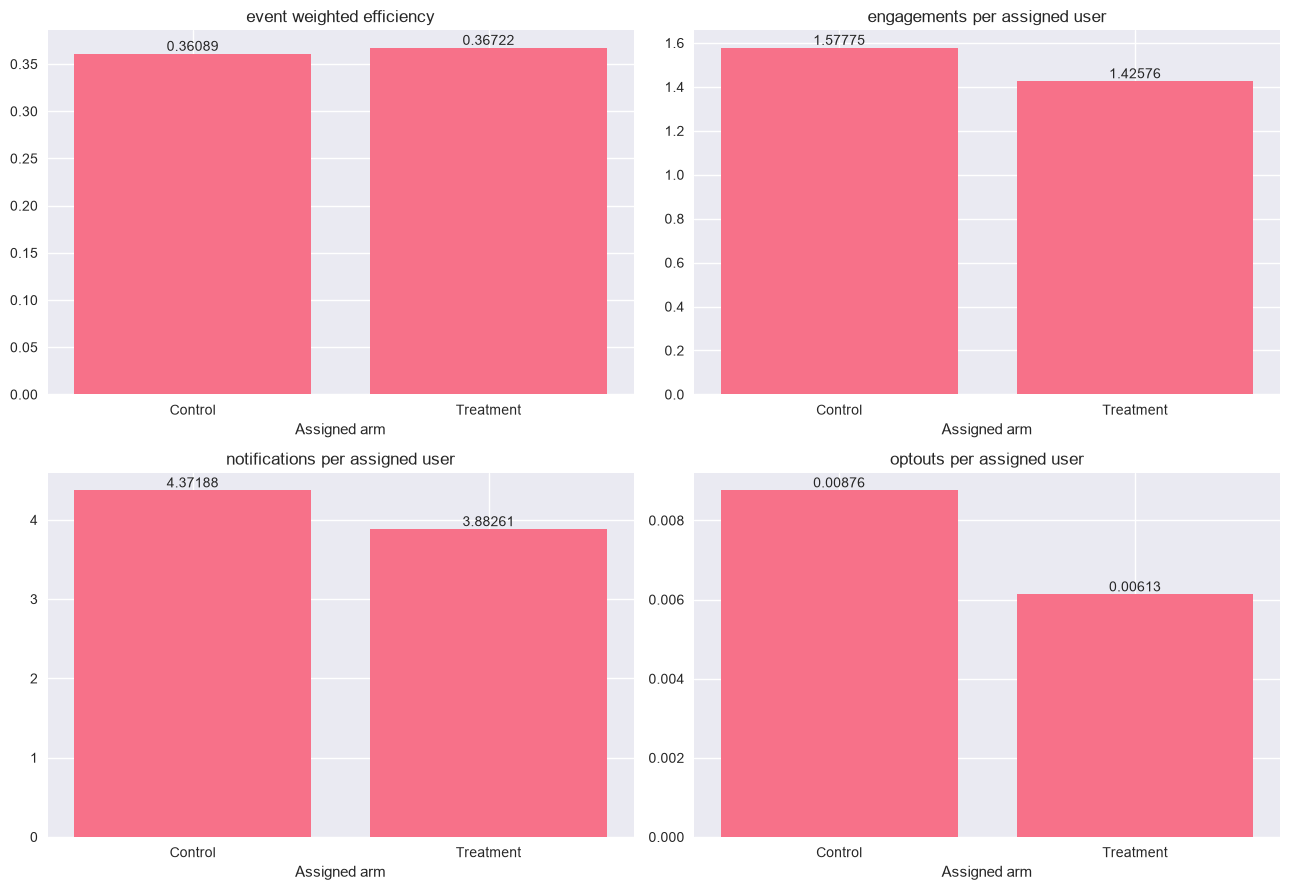

In [16]:
plot_metrics = ['event_weighted_efficiency', 'engagements_per_assigned_user',
                'notifications_per_assigned_user', 'optouts_per_assigned_user']
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for axis, metric in zip(axes.flat, plot_metrics):
    means = experiment_kpis[metric].reindex(['Control', 'Treatment'])
    axis.bar(means.index, means.values)
    axis.set(title=metric.replace('_', ' '), xlabel='Assigned arm')
    axis.bar_label(axis.containers[0], labels=[f'{v:.5f}' for v in means.values])
plt.tight_layout()
plt.show()

The four panels show event-weighted efficiency, engagements per assigned user, eventual notifications per assigned user and opt-out risk. The y-values are absolute rates or per-user counts, not relative percentage changes.

### Assignment balance in supplied profile attributes

Compare the three fixed synthetic profile fields across assigned users using standardized mean differences. Their original creation-time lineage is unverified. Historical March fatigue and opportunity counts are not pre-period baseline attributes and are excluded from this table.

In [17]:
user_baseline = experiment.groupby(["user_id", "arm"]).agg(
    baseline_activity_probability=("baseline_activity_probability", "first"),
    engagement_propensity=("engagement_propensity", "first"),
    fatigue_sensitivity=("fatigue_sensitivity", "first"),
).reset_index()

balance_rows = []
for metric in user_baseline.columns[2:]:
    control = user_baseline.loc[user_baseline["arm"].eq("Control"), metric]
    treatment = user_baseline.loc[user_baseline["arm"].eq("Treatment"), metric]
    pooled_sd = np.sqrt((control.var(ddof=1) + treatment.var(ddof=1)) / 2)
    balance_rows.append({
        "metric": metric,
        "control_mean": control.mean(),
        "treatment_mean": treatment.mean(),
        "standardized_mean_difference": (treatment.mean() - control.mean()) / pooled_sd,
    })
balance = pd.DataFrame(balance_rows)
display(balance)
print(f"Largest absolute standardized mean difference: {balance['standardized_mean_difference'].abs().max():.4f}")

,metric,control_mean,treatment_mean,standardized_mean_difference
0,baseline_activity_probability,0.402050,0.389750,-0.064437
1,engagement_propensity,0.466755,0.454492,-0.059227
2,fatigue_sensitivity,0.465436,0.470059,0.021210


Largest absolute standardized mean difference: 0.0644


These descriptive differences summarize realized assignment balance in the supplied profile fields. They do not prove balance in unmeasured characteristics or validate production feature availability.

## Summary

Print the decision metrics with uncertainty and significance results.

In [18]:
display(experiment_effects)
experiment_kpis.to_csv(project_dir / 'data/processed/phase3_experiment_kpis.csv', index_label='arm')
experiment_effects.to_csv(project_dir / 'data/processed/phase3_experiment_contrasts.csv', index_label='metric')
kpi_population.to_csv(project_dir / 'data/processed/phase3_experiment_users.csv', index=False)
# Preserve old artifact contracts solely for regression verification of Phases 1–2.
legacy_metrics = {'Engagement efficiency': 'engagement_rate', 'Engagements per user': 'engagements',
                  'Notifications per user': 'notifications', 'Immediate notifications per user': 'immediate_notifications',
                  'Opt-outs per user': 'opt_outs'}
legacy_results = pd.DataFrame({name: compare_arms(user_results, column, seed=random_state)
                              for name, column in legacy_metrics.items()}).T
save_simulation(project_dir, simulation_events, simulation_transitions,
                user_results, legacy_results, simulation_checks, dynamics_diagnostics)


,control,treatment,difference,ci_lower,ci_upper,valid_bootstraps,paired
metric,,,,,,,
event_weighted_efficiency,0.360886,0.367216,0.006330,-0.007561,0.020559,2000,False
user_weighted_efficiency_among_recipients,0.360074,0.361903,0.001829,-0.013088,0.017081,2000,False
engagements_per_assigned_user,1.577749,1.425756,-0.151993,-0.220335,-0.083213,2000,False
notifications_per_assigned_user,4.371879,3.882611,-0.489269,-0.582567,-0.393769,2000,False
optouts_per_assigned_user,0.008760,0.006132,-0.002628,-0.007446,0.002628,2000,False
expected_event_weighted_efficiency_on_path,0.365185,0.366143,0.000958,-0.003629,0.005609,2000,False
expected_user_weighted_efficiency_on_path,0.363198,0.362353,-0.000845,-0.005236,0.003551,2000,False
expected_engagements_per_assigned_user_on_path,1.596543,1.421590,-0.174953,-0.215991,-0.133301,2000,False


All results above supersede the independent-row simulation. The stateful scenario maintains consent and delivery history, but its fitted response mechanism, fatigue approximation and fixed historical opportunities still do not identify causal product effects. A real launch decision needs prospective outcomes and predefined acceptable-loss guardrails.

## Insights

- Use the regenerated effect sizes and intervals, not the original simulation headline numbers.
- Include zero-delivery users in randomized-user guardrails.
- Consent cancellation and expiry are real modeled outcomes, not automatic eventual sends.
- Conditional simulation significance cannot validate unknown fatigue/organic-activity dynamics or rare opt-out probabilities.

## Opt-out mechanism sensitivity

Keep fitted engagement scores, policy thresholds, opportunity users, keyed random draws and scheduling fixed. Compare logistic opt-out risks with constant training prevalence and with 0.5x / 2x logistic risks (clipped at one). The multipliers are declared stress scenarios, not estimated mechanisms. Re-run the chronological engine so changed opt-outs affect later consent and deliveries. Results use seed 42 and condition on that realization; they are not uncertainty over all simulator mechanisms.

In [19]:
mechanisms = {
    'logistic': opt_out_response,
    'constant_training_prevalence': lambda cid, state: training_optout_rate,
    'half_logistic': lambda cid, state: min(1., .5 * opt_out_response(cid, state)),
    'double_logistic': lambda cid, state: min(1., 2. * opt_out_response(cid, state)),
}
sensitivity_users, sensitivity_ledgers, sensitivity_rows, sensitivity_checks = [], [], [], {}
for name, response in mechanisms.items():
    if name == 'logistic':
        ledger, checks = simulation_events, simulation_checks
    else:
        ledger, trace, checks = simulate(experiment, history, users, arm_map, engagement_response,
                                         response, dynamics, thresholds, simulation_config)
    population = kpi_users(ledger, arm_map)
    effects = kpi_contrasts(population.loc[population.arm.eq('Control')], population.loc[population.arm.eq('Treatment')])
    risk = binary_summary(population.loc[population.arm.eq('Control'), 'opt_outs'],
                          population.loc[population.arm.eq('Treatment'), 'opt_outs'])
    for metric, row in effects.iterrows():
        sensitivity_rows.append(dict(mechanism=name, metric=metric, **row.to_dict()))
    sensitivity_checks[name] = {**checks, 'user_optout_fisher_p': risk['p_two_sided_equality']}
    sensitivity_users.append(population.assign(mechanism=name))
    sensitivity_ledgers.append(ledger.assign(mechanism=name))
    print(name, checks)
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.loc[sensitivity.metric.isin(['event_weighted_efficiency','engagements_per_assigned_user','optouts_per_assigned_user'])])
sensitivity.to_csv(project_dir / 'data/processed/phase3_optout_sensitivity.csv', index=False)
pd.concat(sensitivity_users, ignore_index=True).to_csv(project_dir / 'data/processed/phase3_sensitivity_users.csv', index=False)
pd.concat(sensitivity_ledgers, ignore_index=True).to_csv(project_dir / 'data/processed/phase3_sensitivity_events.csv', index=False)
(project_dir / 'data/processed/phase3_sensitivity_checks.json').write_text(json.dumps(sensitivity_checks, indent=2) + '\n')

logistic {'candidates': 19856, 'attempts': 25924, 'deliveries_after_unsubscribe': 0, 'engagements_after_unsubscribe': 0, 'chronology_exposure_fatigue_consent_checks': 'passed'}


constant_training_prevalence {'candidates': 19856, 'attempts': 25924, 'deliveries_after_unsubscribe': 0, 'engagements_after_unsubscribe': 0, 'chronology_exposure_fatigue_consent_checks': 'passed'}


half_logistic {'candidates': 19856, 'attempts': 25934, 'deliveries_after_unsubscribe': 0, 'engagements_after_unsubscribe': 0, 'chronology_exposure_fatigue_consent_checks': 'passed'}


double_logistic {'candidates': 19856, 'attempts': 25879, 'deliveries_after_unsubscribe': 0, 'engagements_after_unsubscribe': 0, 'chronology_exposure_fatigue_consent_checks': 'passed'}


,mechanism,metric,control,treatment,difference,ci_lower,ci_upper,valid_bootstraps,paired
0,logistic,event_weighted_efficiency,0.360886,0.367216,0.006330,-0.007561,0.020559,2000,False
2,logistic,engagements_per_assigned_user,1.577749,1.425756,-0.151993,-0.220335,-0.083213,2000,False
4,logistic,optouts_per_assigned_user,0.008760,0.006132,-0.002628,-0.007446,0.002628,2000,False
8,constant_training_prevalence,event_weighted_efficiency,0.360886,0.367216,0.006330,-0.007639,0.020541,2000,False
10,constant_training_prevalence,engagements_per_assigned_user,1.577749,1.425756,-0.151993,-0.220324,-0.083213,2000,False
12,constant_training_prevalence,optouts_per_assigned_user,0.010074,0.006132,-0.003942,-0.009198,0.001314,2000,False
16,half_logistic,event_weighted_efficiency,0.360689,0.367099,0.006410,-0.007514,0.020645,2000,False
18,half_logistic,engagements_per_assigned_user,1.578625,1.427070,-0.151555,-0.219032,-0.082786,2000,False
20,half_logistic,optouts_per_assigned_user,0.005694,0.002190,-0.003504,-0.007446,0.000000,2000,False
24,double_logistic,event_weighted_efficiency,0.361659,0.367391,0.005732,-0.007949,0.019714,2000,False


1059